
# SaaS Customer Churn — EDA and Baseline Experiments

Project goal is to test whether product engagement data improves next-month churn prediction compared with subscription/billing alone. We evaluate customer prioritization as well as predictive scores, because a retention team may be able to review only the highest-risk 20% of accounts each month.

Dataset: Publicly accessible synthetic B2B SaaS customer-month data.

The target variable is `churned_next_month`. Each customer can appear across multiple months.

These results describe simulated customer behavior and do not establish causal relationships or performance in real companies.


## Reproducible Environment

This section imports the required Python libraries and initializes the project settings.

- 'Seed=42' helps make random operations reproducible.
- 'results/full/' stores figures and experiment results.
- 'data/raw/' contains downloaded source data

In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from huggingface_hub import hf_hub_download

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "churned_next_month"

# Find our project folder if VS Code starts in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw"
RESULT_DIR = ROOT / "results" / "full"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("Project:", ROOT)

/Users/yokibhachapagain/eas510-project2-yokibhac/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: /Users/yokibhachapagain/eas510-project2-yokibhac


## Read and inspect the monthly source table

Each row is a customer-month. The same customer can appear in several months. user_id is an identifier, not a predictive feature. The final label asks whether the account churns next month.

In [2]:
#Load Hugging Face dataset

path = DATA_DIR / "user_monthly.parquet"
if not path.exists():
    hf_hub_download(
        repo_id="arti199919/synthetic-saas-churn-sample",
        repo_type="dataset",
        filename="user_monthly.parquet",
        local_dir=DATA_DIR,
    )

monthly = pd.read_parquet(path)
monthly["month"] = pd.to_datetime(monthly["month"])
monthly = monthly.sort_values(["user_id", "month"]).reset_index(drop=True)

print(f"Rows: {len(monthly):,}")
print(f"Customers: {monthly['user_id'].nunique():,}")
print(f"Period: {monthly['month'].min():%b %Y} to {monthly['month'].max():%b %Y}")
display(monthly.head())

Rows: 79,817
Customers: 5,000
Period: Jan 2024 to Dec 2025


,user_id,month,tenure_month,plan_type,monthly_price,mrr,sessions,feature_usage_score,support_tickets,payment_failures,churned,churned_next_month,nps_score,product_incident,active_seats
0,U0000001,2024-11-01,0,Starter,80.309776,80.309776,26,48.976616,0,0,0,0,5,0,3
1,U0000001,2024-12-01,1,Starter,80.309776,80.309776,22,56.088699,0,0,0,0,7,0,4
2,U0000001,2025-01-01,2,Starter,80.309776,80.309776,36,65.155914,1,0,0,0,5,0,4
3,U0000001,2025-02-01,3,Starter,80.309776,80.309776,22,41.172787,1,1,0,0,5,0,3
4,U0000001,2025-03-01,4,Starter,80.309776,80.309776,30,48.689457,1,0,0,0,6,0,3


## Audit data quality and the target

Checks: Null values, duplicated (user_id, month) pairs, whether mrr repeats monthly_price, and whether the next-month target agrees with the following month's recorded churn event.

Why: Duplicate rows can affect results, and redundant features may not add useful information. We also check that churn labels are consistent, although this doesn't guarantee the data is free from future information.

In [3]:
print("Missing values:", int(monthly.isna().sum().sum()))
print("Duplicate customer-months:", int(monthly.duplicated(["user_id", "month"]).sum()))
print("Price equals MRR:", f"{np.isclose(monthly['monthly_price'], monthly['mrr']).mean():.1%}")

# next-month label should agree with the next observed month's churn status.
next_month = monthly.groupby("user_id")["month"].shift(-1)
next_churn = monthly.groupby("user_id")["churned"].shift(-1)
consecutive = next_month.eq(monthly["month"] + pd.DateOffset(months=1))
match_rate = monthly.loc[consecutive, TARGET].eq(next_churn[consecutive]).mean()
print("Next-month label agreement:", f"{match_rate:.1%}")

if monthly.duplicated(["user_id", "month"]).any():
    raise ValueError("Found duplicate customer-month records. Investigate before modeling.")

Missing values: 0
Duplicate customer-months: 0
Price equals MRR: 100.0%
Next-month label agreement: 100.0%


## Define the population eligible for next-month churn prediction
We only predict for accounts that have not already churned. We also exclude the final observed month, because the dataset does not provide the next observed month to verify its outcome.

In [4]:
last_month = monthly["month"].max()
work = monthly.loc[
    (monthly["churned"] == 0) &
    (monthly["month"] < last_month)
].copy()

print(f"Eligible customer-months: {len(work):,}")
print(f"Churn events next month: {work[TARGET].sum():,}")
print(f"Churn rate: {work[TARGET].mean():.2%}")

Eligible customer-months: 74,817
Churn events next month: 1,056
Churn rate: 1.41%


##  EDA: Does churn vary by plan, engagement, and calendar month?
We compare group-level churn rates and the average usage of accounts that stay vs accounts that churn next month. Differences are associations, not proof that a plan or behavior causes cancellation. Customer composition and tenure may explain part of the difference.

In [5]:
plan_summary = work.groupby("plan_type", observed=True).agg(
    observations=(TARGET, "size"),
    churn_events=(TARGET, "sum"),
    churn_rate=(TARGET, "mean"),
).sort_values("churn_rate", ascending=False)

usage_summary = work.groupby(TARGET)[
    ["sessions", "feature_usage_score", "active_seats"]
].mean().round(2)

monthly_churn = work.groupby("month")[TARGET].mean()

print("Churn by plan:")
display(plan_summary.round(4))
print("Average engagement (0 = stayed; 1 = churned next month):")
display(usage_summary)

Churn by plan:


,observations,churn_events,churn_rate
plan_type,,,
Starter,33779,596,0.0176
Enterprise,1398,19,0.0136
Pro,27026,326,0.0121
Business,12614,115,0.0091


Average engagement (0 = stayed; 1 = churned next month):


,sessions,feature_usage_score,active_seats
churned_next_month,,,
0,29.95,47.189999,6.65
1,19.14,27.389999,3.40


## Visualize observed churn patterns

The time plot describes next-month churn among eligible accounts. The plan plot uses the same eligibility filter. A small number of churn events can make rates fluctuate, so counts are inspected alongside percentages.

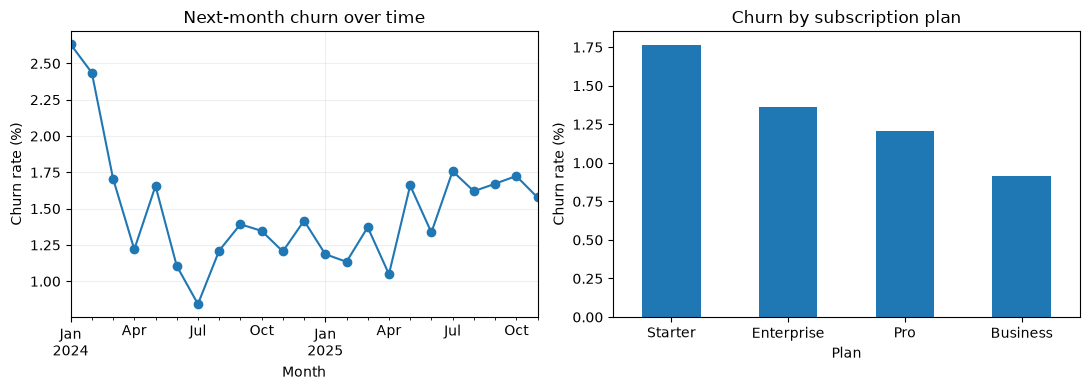

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

(monthly_churn * 100).plot(ax=axes[0], marker="o")
axes[0].set(title="Next-month churn over time", ylabel="Churn rate (%)", xlabel="Month")
axes[0].grid(alpha=0.2)

(plan_summary["churn_rate"] * 100).plot.bar(ax=axes[1])
axes[1].set(title="Churn by subscription plan", ylabel="Churn rate (%)", xlabel="Plan")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
fig.savefig(RESULT_DIR / "eda_churn_patterns.png", dpi=150)
plt.show()

## EDA: tenure and payment friction

Research question: Are accounts earlier in their subscription lifecycle more likely to churn? Do accounts with payment failures have a different next-month churn rate?

These analyses add useful counts and rates rather than an unlimited list of plots. They will help explain why subscription information may be predictive independently of engagement. The groups may differ in other ways, so these are not causal effects.

In [7]:
tenure_groups = work.assign(
    tenure_band=pd.cut(work["tenure_month"],
                       bins=[-1, 2, 5, 11, 23, float("inf")],
                       labels=["0-2", "3-5", "6-11", "12-23", "24+"])
).groupby("tenure_band", observed=True)[TARGET].agg(["size", "sum", "mean"])
tenure_groups.columns = ["customer_months", "churn_events", "churn_rate"]

payment_groups = work.assign(
    payment_status=np.where(work["payment_failures"] > 0,
                            "One or more failures", "No failure")
).groupby("payment_status")[TARGET].agg(["size", "sum", "mean"])
payment_groups.columns = ["customer_months", "churn_events", "churn_rate"]

print("Next-month churn by tenure band:")
display(tenure_groups.round(4))
print("Next-month churn by payment failure status:")
display(payment_groups.round(4))

Next-month churn by tenure band:


,customer_months,churn_events,churn_rate
tenure_band,,,
0-2,14536,223,0.0153
3-5,13922,161,0.0116
6-11,26127,322,0.0123
12-23,20232,350,0.0173


Next-month churn by payment failure status:


,customer_months,churn_events,churn_rate
payment_status,,,
No failure,64379,737,0.0114
One or more failures,10438,319,0.0306


## EDA: quantify behavioral differences

Question: How large are the average engagement gaps between accounts that stay and those that churn next month? The comparison helps prioritize which signals to test but must not be interpreted as causal.


In [8]:
behavior_cols = ["sessions", "feature_usage_score", "active_seats",
                 "support_tickets", "payment_failures"]
behavior_by_outcome = (
    work.groupby(TARGET)[behavior_cols].mean().T
    .rename(columns={0: "Stayed", 1: "Churned next month"})
)
behavior_by_outcome["difference (churn - stay)"] = (
    behavior_by_outcome["Churned next month"] - behavior_by_outcome["Stayed"]
)
display(behavior_by_outcome.round(2))

churned_next_month,Stayed,Churned next month,difference (churn - stay)
sessions,29.95,19.14,-10.80
feature_usage_score,47.19,27.39,-19.80
active_seats,6.65,3.40,-3.25
support_tickets,1.09,1.90,0.81
payment_failures,0.15,0.35,0.20


## EDA: one actual customer's history before churn

An account in the dataset is selected with a known next-month churn event and inspect its last six observed eligible records. This is qualitative context, not evidence that all customers follow the same pattern.

In [9]:
churn_ids = work.loc[work[TARGET] == 1, "user_id"].unique()
if len(churn_ids):
    example_id = churn_ids[0]
    history = work.loc[work["user_id"].eq(example_id)].sort_values("month")
    print("Illustrative account:", example_id)
    display(history[["month", "sessions", "feature_usage_score",
                     "payment_failures", "churned_next_month"]].tail(6))
else:
    print("No eligible churn events were found.")

Illustrative account: U0000002


,month,sessions,feature_usage_score,payment_failures,churned_next_month
27,2025-03-01,19,30.212614,0,0
28,2025-04-01,22,28.627295,0,0
29,2025-05-01,17,32.740555,0,0
30,2025-06-01,20,29.192045,0,0
31,2025-07-01,14,30.168793,0,0
32,2025-08-01,7,15.821863,1,1


## Three controlled feature-group experiments

a. Billing only: tenure, plan, monthly price, payment failures.
b. Engagement only: sessions, feature-usage score, active seats.
c. Combined: both groups.

mrr is excluded because it exactly duplicates price in the inspected data. churned_next_month is the label, and churned/`user_id` are not model input features. Support tickets and satisfaction are intentionally outside this first comparison.

In [10]:
billing = ["tenure_month", "plan_type", "monthly_price", "payment_failures"]
engagement = ["sessions", "feature_usage_score", "active_seats"]

feature_groups = {
    "billing": billing,
    "engagement": engagement,
    "combined": billing + engagement,
}

for name, columns in feature_groups.items():
    print(f"{name}: {columns}")

billing: ['tenure_month', 'plan_type', 'monthly_price', 'payment_failures']
engagement: ['sessions', 'feature_usage_score', 'active_seats']
combined: ['tenure_month', 'plan_type', 'monthly_price', 'payment_failures', 'sessions', 'feature_usage_score', 'active_seats']


## Split by time before modeling

We train on earlier months, choose between approaches on validation months, and examine predictions on later months. February and July 2025 are unused gaps. This prevents direct random mixing of future months into training.

In [11]:
train = work[work["month"] <= "2025-01-01"].copy()
val = work[work["month"].between("2025-03-01", "2025-06-01")].copy()
test = work[work["month"].between("2025-08-01", "2025-11-01")].copy()

for name, frame in [("Train", train), ("Validation", val), ("Later test", test)]:
    print(f"{name:>10}: {len(frame):>6,} rows | "
          f"{frame['month'].min():%b %Y}–{frame['month'].max():%b %Y} | "
          f"churn {frame[TARGET].mean():.2%}")
    if frame[TARGET].nunique() != 2:
        raise ValueError(f"{name} must include both classes.")

     Train: 32,545 rows | Jan 2024–Jan 2025 | churn 1.32%
Validation: 17,433 rows | Mar 2025–Jun 2025 | churn 1.35%
Later test: 16,134 rows | Aug 2025–Nov 2025 | churn 1.65%


## Define decision-oriented metrics

Average Precision (AP): evaluates the overall ranking of rare churn events. A no-skill score is approximately the churn prevalence.

Recall@Top20%: Within each observation month, rank customers by predicted risk and select the highest-risk 20%. Then divide the number of actual future churners in those selected accounts by all future churners in the evaluated months.

Precision@Top20%: Of the accounts selected for review, what fraction actually churns next month?

F1 at threshold 0.5: Evaluates binary yes/no predictions using the default threshold. With rare events, F1 may be zero even if AP and top-20% ranking are useful.

In [12]:
def evaluate(frame, probabilities):
    """Evaluate customer ranking and ordinary classification at a 0.5 threshold."""
    y = frame[TARGET].to_numpy()
    probabilities = np.asarray(probabilities)
    selected = np.zeros(len(frame), dtype=bool)
    rng = np.random.default_rng(SEED)  # stable random order when scores tie

    # A SaaS team can review the top 20% of active accounts each month.
    for _, rows in frame.reset_index(drop=True).groupby("month"):
        indices = rows.index.to_numpy()
        count = math.ceil(0.20 * len(indices))
        order = np.lexsort((rng.random(len(indices)), -probabilities[indices]))
        selected[indices[order[:count]]] = True

    captured = int(np.sum(selected & (y == 1)))
    total_churn = int(np.sum(y == 1))
    selected_count = int(selected.sum())
    predicted = (probabilities >= 0.5).astype(int)

    return {
        "AP": average_precision_score(y, probabilities),
        "Recall@20%": captured / total_churn,
        "Precision@20%": captured / selected_count,
        "Captured churners": captured,
        "Selected accounts": selected_count,
        "F1 at 0.5": f1_score(y, predicted, zero_division=0),
    }

## Candidate models and leakage-safe preprocessing

We test three existing algorithms rather than inventing a new one. Logistic Regression is an interpretable linear reference; the Decision Tree captures threshold-like rules; Random Forest averages multiple trees.

The Pipeline fits scaling and categorical one-hot encoding only on the training period. This avoids learning preprocessing parameters from validation or later months

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=40, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=120, max_depth=12, min_samples_leaf=20,
        random_state=SEED, n_jobs=-1,
    ),
}

def make_pipeline(columns, model):
    numeric = [name for name in columns if name != "plan_type"]
    steps = [("numbers", StandardScaler(), numeric)]
    if "plan_type" in columns:
        steps.append(("plan", OneHotEncoder(handle_unknown="ignore"), ["plan_type"]))
    return Pipeline([
        ("preprocessing", ColumnTransformer(steps)),
        ("model", clone(model)),
    ])

## Fit models on training data; compare on validation

The dummy model predicts the training-period event rate for everyone and provides a baseline. All three model types are tested using exactly the same billing, engagement, and combined feature groups.

Observation from the table: Larger AP and Recall@20% are better for ranking. Selection should depend on the validation results, not on whichever happens to score best on the later period.

In [14]:
fitted = {}
validation_rows = []

# Simple reference: everyone gets the training-period churn rate.
dummy = DummyClassifier(strategy="prior")
dummy.fit(train[["tenure_month"]], train[TARGET])
p = dummy.predict_proba(val[["tenure_month"]])[:, 1]
validation_rows.append({"features": "none", "model": "Dummy", **evaluate(val, p)})

for feature_name, columns in feature_groups.items():
    for model_name, model in models.items():
        pipeline = make_pipeline(columns, model)
        pipeline.fit(train[columns], train[TARGET])
        p = pipeline.predict_proba(val[columns])[:, 1]

        fitted[(feature_name, model_name)] = pipeline
        validation_rows.append({
            "features": feature_name,
            "model": model_name,
            **evaluate(val, p),
        })

validation_results = pd.DataFrame(validation_rows)
display(validation_results[["features", "model", "AP", "Recall@20%", "Precision@20%"]].round(3))
validation_results.to_csv(RESULT_DIR / "validation_model_comparison.csv", index=False)

,features,model,AP,Recall@20%,Precision@20%
0,none,Dummy,0.014,0.225,0.015
1,billing,Logistic Regression,0.038,0.390,0.026
2,billing,Decision Tree,0.021,0.377,0.026
3,billing,Random Forest,0.019,0.322,0.022
4,engagement,Logistic Regression,0.053,0.661,0.045
5,engagement,Decision Tree,0.043,0.576,0.039
6,engagement,Random Forest,0.046,0.614,0.042
7,combined,Logistic Regression,0.067,0.691,0.047
8,combined,Decision Tree,0.048,0.572,0.039
9,combined,Random Forest,0.053,0.644,0.044


## Select by validation AP; evaluate on later months

We select the highest-validation-AP algorithm separately for each feature group. Measure its ranking on Aug–Nov 2025 without retraining on those months. The later-period scores are preliminary evidence and should not guide further tuning so that we preserve a valid final comparison.

In [15]:
selected_models = (
    validation_results[validation_results["features"] != "none"]
    .sort_values("AP", ascending=False)
    .drop_duplicates("features")
)

print("Models selected using validation AP:")
display(selected_models[["features", "model", "AP"]].round(3))

test_rows = []
p_dummy = dummy.predict_proba(test[["tenure_month"]])[:, 1]
test_rows.append({"features": "none", "model": "Dummy", **evaluate(test, p_dummy)})

for _, row in selected_models.iterrows():
    feature_name, model_name = row["features"], row["model"]
    columns = feature_groups[feature_name]
    p = fitted[(feature_name, model_name)].predict_proba(test[columns])[:, 1]
    test_rows.append({"features": feature_name, "model": model_name, **evaluate(test, p)})

test_results = pd.DataFrame(test_rows).set_index("features")
order = ["none", "billing", "engagement", "combined"]
test_results = test_results.reindex(order)

display(test_results[[
    "model", "AP", "Recall@20%", "Precision@20%",
    "Captured churners", "Selected accounts", "F1 at 0.5",
]].round(3))
test_results.to_csv(RESULT_DIR / "test_model_comparison.csv")

Models selected using validation AP:


,features,model,AP
7,combined,Logistic Regression,0.067
4,engagement,Logistic Regression,0.053
1,billing,Logistic Regression,0.038


,model,AP,Recall@20%,Precision@20%,Captured churners,Selected accounts,F1 at 0.5
features,,,,,,,
none,Dummy,0.016,0.184,0.015,49,3228,0.0
billing,Logistic Regression,0.031,0.380,0.031,101,3228,0.0
engagement,Logistic Regression,0.050,0.530,0.044,141,3228,0.0
combined,Logistic Regression,0.053,0.586,0.048,156,3228,0.0


## Summarize ranking quality visually

The left plot compares the fraction of actual future churners captured in the highest-risk fifth of accounts each month. The right plot shows AP, where an improvement must be interpreted relative to the rare-event baseline.

Observation: A model can rank customers usefully yet still select many accounts who do not churn.

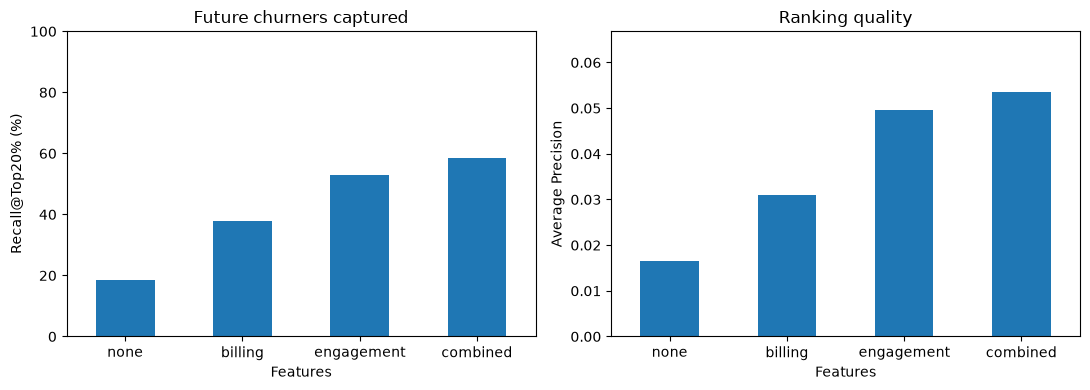

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

test_results["Recall@20%"].mul(100).plot.bar(ax=axes[0])
axes[0].set(title="Future churners captured", ylabel="Recall@Top20% (%)", xlabel="Features")
axes[0].set_ylim(0, 100)

test_results["AP"].plot.bar(ax=axes[1])
axes[1].set(title="Ranking quality", ylabel="Average Precision", xlabel="Features")
axes[1].set_ylim(0, test_results["AP"].max() * 1.25)

for ax in axes:
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
fig.savefig(RESULT_DIR / "test_model_comparison.png", dpi=150)
plt.show()

## Interpretation and limits

We use the printed values to state whether engagement is helpful beyond billing, and whether the combined feature group adds anything beyond engagement alone. 

Limits: The data are synthetic; the same accounts occur repeatedly; simple patterns may be embedded in the simulator; and predicted risk is not the causal impact of a retention intervention. Historic trends and statistical uncertainty require separate experiments.

In [17]:
billing_recall = test_results.loc["billing", "Recall@20%"]
engagement_recall = test_results.loc["engagement", "Recall@20%"]
combined_recall = test_results.loc["combined", "Recall@20%"]
combined_precision = test_results.loc["combined", "Precision@20%"]

print(f"Billing-only Recall@20%: {billing_recall:.1%}")
print(f"Engagement-only Recall@20%: {engagement_recall:.1%}")
print(f"Combined Recall@20%: {combined_recall:.1%}")
print(f"Combined improvement over billing: {(combined_recall-billing_recall)*100:.1f} percentage points")
print(f"Combined Precision@20%: {combined_precision:.1%}")
print(f"Churn prevalence in later period: {test[TARGET].mean():.1%}")
print("Figures and results saved in:", RESULT_DIR)

Billing-only Recall@20%: 38.0%
Engagement-only Recall@20%: 53.0%
Combined Recall@20%: 58.6%
Combined improvement over billing: 20.7 percentage points
Combined Precision@20%: 4.8%
Churn prevalence in later period: 1.6%
Figures and results saved in: /Users/yokibhachapagain/eas510-project2-yokibhac/results/full
